# SAMS Vision: distance estimation training

This notebook trains the residual distance network used by `monitoring/services/distance_estimation.py`. Live inference loads `models/vision/distance/distance_nn.pt` and reads calibration from `models/vision/distance/calib.json` (`fy_px`, `person_height_m`, `tof_near_m`, `hidden`).

Distance is modeled as **Z = Z0 * exp(delta)** where Z0 is a pinhole prior from body height and apparent size.

## Dataset

[Human tracking dataset](https://data.mendeley.com/datasets/493s6f753v/2) (DOI `10.17632/493s6f753v.2`).

## Experiments

| Id | Method |
|----|--------|
| dist_exp01_pinhole_z0 | Pinhole Z0 only |
| dist_exp02_ridge | Ridge on features |
| dist_exp03_residual_mlp | Residual MLP (SAMS architecture) |
| dist_exp04_absolute_mlp | Direct Z regression |
| dist_exp05_residual_pose_only | Residual MLP, pose rows only |
| dist_exp06_residual_log_huber | Residual MLP, Huber on log Z |

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, FEATURE_NAMES |
| 1 | Download Mendeley subset |
| 2 | Build labeled feature table |
| 3 | EDA, previews, PCA |
| 4 | Subject holdout split |
| 5 | Training utilities (early stopping on val MAE) |
| 6 | Experiments and comparison |
| 7 | Export distance_nn.pt, calib.json, model card |
| 8 | Fine-tune on this site's labelled rows (`site/`) |
| 9 | Limitations |

## Rules

1. Splits group by **subject**, not by frame.
2. `FEATURE_NAMES` match `distance_estimation.py` exactly.
3. `ResidualDistanceMLP` matches the live module layout.
4. Tables as DataFrames with CSV; charts as PNG.

## 0. Setup

### 0.1 Paths

In [18]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "vision" / "distance" / "mendeley_493s6f753v",
    SAMS_ROOT / "models" / "vision" / "distance",
    SAMS_ROOT / "results" / "vision" / "distance",
]:
    folder.mkdir(parents=True, exist_ok=True)

In [19]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "distance"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "distance"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "distance" / "mendeley_493s6f753v"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 0.2 Packages

In [20]:
import subprocess, sys
PACKAGES = ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "scipy", "torch", "tqdm"]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])

In [21]:
import gc
import json
import math
import time
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from numpy.linalg import svd
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

DEVICE: cuda


### 0.3 Configuration

In [22]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "distance"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "distance"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "distance" / "mendeley_493s6f753v"

for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:   ", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/vision/distance
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vision/distance
DATA_DIR:    /content/SAMS/datasets/vision/distance/mendeley_493s6f753v


In [ ]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

HIDDEN = (64, 32)
MAX_EPOCHS = 80
PATIENCE = 10
LR = 1e-3
BATCH_SIZE = 64

PERSON_HEIGHT_M = 1.7
TOF_NEAR_M = 1.5
FY_PX_DEFAULT = 753.8742631289133

config_table = pd.DataFrame([
    {"setting": "SEED", "value": SEED, "meaning": "Random seed for splits and training"},
    {"setting": "HIDDEN", "value": str(HIDDEN), "meaning": "Residual MLP hidden layers (live calib.json)"},
    {"setting": "MAX_EPOCHS", "value": MAX_EPOCHS, "meaning": "Upper epoch limit"},
    {"setting": "PATIENCE", "value": PATIENCE, "meaning": "Early stopping on validation MAE"},
    {"setting": "LR", "value": LR, "meaning": "AdamW learning rate"},
    {"setting": "BATCH_SIZE", "value": BATCH_SIZE, "meaning": "Mini-batch size"},
    {"setting": "PERSON_HEIGHT_M", "value": PERSON_HEIGHT_M, "meaning": "Stature in the live pinhole prior"},
    {"setting": "TOF_NEAR_M", "value": TOF_NEAR_M, "meaning": "Range the ToF sensor owns in deployment"},
    {"setting": "FY_PX_DEFAULT", "value": FY_PX_DEFAULT, "meaning": "Focal length if no camera matrix is read"},
]).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

### 0.4 FEATURE_NAMES (live contract)

In [23]:
FEATURE_NAMES = [
    "rel_h",
    "rel_w",
    "aspect",
    "cx_norm",
    "cy_norm",
    "bottom_y_norm",
    "inv_rel_h",
    "log_z0",
    "det_conf",
    "pose_available",
    "pose_height_rel",
    "shoulder_width_rel",
    "hip_width_rel",
    "torso_rel",
    "pose_conf_mean",
    "pose_inv_height",
]
FEATURE_DIM = len(FEATURE_NAMES)
display(pd.DataFrame({"index": range(FEATURE_DIM), "name": FEATURE_NAMES}))

,index,name
0,0,rel_h
1,1,rel_w
2,2,aspect
3,3,cx_norm
4,4,cy_norm
5,5,bottom_y_norm
6,6,inv_rel_h
7,7,log_z0
8,8,det_conf
9,9,pose_available


### 0.5 Helpers

In [24]:
def save_table(frame: pd.DataFrame, name: str) -> None:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)


def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    return {
        "mae": float(np.mean(np.abs(err))),
        "medae": float(np.median(np.abs(err))),
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mean_rel_err": float(np.mean(np.abs(err) / np.clip(y_true, 1e-3, None))),
    }


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")

## 1. Download Mendeley subset

We fetch the public file index and download subjects TDB_001 through TDB_004 for A-POSE and RUNNING.

In [25]:
# --- Mendeley file index + selective download --------------------------------
import urllib.request

MENDELEY_ID = "493s6f753v"
DOI = "10.17632/493s6f753v.2"
API_FILES = f"https://data.mendeley.com/api/datasets/{MENDELEY_ID}/files"

UA = {"User-Agent": "SAMS-distance-notebook/1.0 (research; campus project)"}

def http_json(url: str) -> Any:
    req = urllib.request.Request(url, headers=UA)
    with urllib.request.urlopen(req, timeout=120) as resp:
        return json.load(resp)

def download(url: str, dest: Path) -> None:
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        return
    req = urllib.request.Request(url, headers=UA)
    with urllib.request.urlopen(req, timeout=300) as resp, open(dest, "wb") as f:
        while True:
            chunk = resp.read(1 << 20)
            if not chunk:
                break
            f.write(chunk)

print("Fetching Mendeley file index (first page)...")
file_index = http_json(API_FILES)
print(f"Indexed {len(file_index)} files on page 1 (API returns at most 100; the full set is larger on the website).")

by_name = {f["filename"]: f for f in file_index}

SUBJECTS = ["TDB_001_F", "TDB_002_F", "TDB_003_M", "TDB_004_F"]
MOVEMENTS = ["A-POSE", "RUNNING"]  # compact + some locomotion
want = ["SUBJECTS_CHARACTERISTICS.csv"]
for subj in SUBJECTS:
    for mov in MOVEMENTS:
        for kind, ext in [("KP2D", "json"), ("KP3D", "trc")]:
            want.append(f"{subj}__{mov}__{kind}.{ext}")

missing = [w for w in want if w not in by_name]
print("Requested:", len(want), "| missing from API page:", missing)

for name in want:
    if name not in by_name:
        continue
    meta = by_name[name]
    dest = DATA_DIR / name
    print(f"Downloading {name} ({meta['size']/1e6:.2f} MB)")
    download(meta["content_details"]["download_url"], dest)

print("Done. Files on disk:", sorted(p.name for p in DATA_DIR.glob('*'))[:20], "...")

Fetching Mendeley file index (first page)...
Indexed 100 files on page 1 (API returns at most 100; the full set is larger on the website).
Requested: 17 | missing from API page: []
Done. Files on disk: ['SUBJECTS_CHARACTERISTICS.csv', 'TDB_001_F__A-POSE__KP2D.json', 'TDB_001_F__A-POSE__KP3D.trc', 'TDB_001_F__RUNNING__KP2D.json', 'TDB_001_F__RUNNING__KP3D.trc', 'TDB_002_F__A-POSE__KP2D.json', 'TDB_002_F__A-POSE__KP3D.trc', 'TDB_002_F__RUNNING__KP2D.json', 'TDB_002_F__RUNNING__KP3D.trc', 'TDB_003_M__A-POSE__KP2D.json', 'TDB_003_M__A-POSE__KP3D.trc', 'TDB_003_M__RUNNING__KP2D.json', 'TDB_003_M__RUNNING__KP3D.trc', 'TDB_004_F__A-POSE__KP2D.json', 'TDB_004_F__A-POSE__KP3D.trc', 'TDB_004_F__RUNNING__KP2D.json', 'TDB_004_F__RUNNING__KP3D.trc', 'distance_features_labeled.csv'] ...


## 2. Parse keypoints and build labeled features

Each row holds `FEATURE_NAMES`, ground-truth `distance_m`, and pinhole prior `z0_m`.

In [26]:
# --- Parsers: TRC 3D, camera centre, MediaPipe features ----------------------
# MediaPipe Pose landmark indices
MP_NOSE, MP_L_SHO, MP_R_SHO = 0, 11, 12
MP_L_HIP, MP_R_HIP = 23, 24
MP_L_ANK, MP_R_ANK = 27, 28


def load_subjects_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep=";")
    df.columns = [c.strip() for c in df.columns]
    df = df.rename(columns={
        "Subject_code": "subject",
        "Height (cm)": "height_cm",
        "Weight (kg)": "weight_kg",
        "Age (years)": "age",
        "Sex": "sex",
    })
    df["height_m"] = df["height_cm"].astype(float) / 100.0
    return df


def load_trc_frames(path: Path) -> Dict[int, np.ndarray]:
    """Return {frame_idx: (33,3) XYZ metres}."""
    out: Dict[int, np.ndarray] = {}
    for ln in path.read_text(errors="replace").splitlines():
        if not ln or not ln[0].isdigit() or ln.startswith("90\t90"):
            continue
        parts = ln.split("\t")
        if len(parts) < 2 + 99:
            continue
        try:
            fr = int(float(parts[0]))
            xyz = np.array([float(x) for x in parts[2:2 + 99]], dtype=np.float64).reshape(33, 3)
        except ValueError:
            continue
        out[fr] = xyz
    return out


def camera_center_from_P(P: np.ndarray) -> np.ndarray:
    """Camera centre C in world coords: P @ [C;1] = 0."""
    _, _, vh = svd(P.astype(np.float64))
    C = vh[-1]
    return C[:3] / C[3]


def focal_y_px(P: np.ndarray) -> float:
    """fy from the camera matrix inside a 3x4 projection.

    P = K [R|t]. RQ on the left 3x3 recovers K; fy is K[1, 1] after the
    diagonal is made positive and K[2, 2] is normalised to 1.
    """
    from scipy.linalg import rq

    M = np.asarray(P, dtype=float).reshape(3, 4)[:, :3]
    K, _R = rq(M)
    signs = np.sign(np.diag(K))
    signs[signs == 0] = 1.0
    K = K @ np.diag(signs)
    K = K / K[2, 2]
    return float(abs(K[1, 1]))


def estimate_image_size(keypoints_uvs: List[np.ndarray]) -> Tuple[int, int]:
    umax = max(float(k[:, 0].max()) for k in keypoints_uvs) if keypoints_uvs else 480
    vmax = max(float(k[:, 1].max()) for k in keypoints_uvs) if keypoints_uvs else 480
    # MediaPipe virtual views in this set are roughly square ~414; pad to safe canvas
    W = int(max(480, math.ceil(umax / 32) * 32 + 32))
    H = int(max(480, math.ceil(vmax / 32) * 32 + 32))
    return W, H


def mp_to_features(
    kps: np.ndarray,
    image_wh: Tuple[int, int],
    *,
    person_height_m: float,
    fy_px: float,
    det_conf: float = 0.9,
) -> Tuple[np.ndarray, float, List[float]]:
    """Build SAMS FEATURE_NAMES vector + Z0 from MediaPipe (33,3)=(u,v,score).

    Also returns xyxy bbox [x1,y1,x2,y2] for optional viz / YOLO-parity.
    """
    w, h = image_wh
    conf = kps[:, 2]
    valid = conf >= 0.3
    if valid.sum() < 4:
        raise ValueError("too few keypoints")

    u = kps[:, 0]
    v = kps[:, 1]
    x1, x2 = float(u[valid].min()), float(u[valid].max())
    y1, y2 = float(v[valid].min()), float(v[valid].max())
    bw, bh = max(1.0, x2 - x1), max(1.0, y2 - y1)
    rel_h, rel_w = bh / h, bw / w
    aspect = bh / bw
    cx_norm = ((x1 + x2) * 0.5) / w
    cy_norm = ((y1 + y2) * 0.5) / h
    bottom_y_norm = y2 / h

    pose_available = 0.0
    pose_height_rel = shoulder_width_rel = hip_width_rel = torso_rel = 0.0
    pose_conf_mean = float(conf[valid].mean())
    pose_inv_height = 0.0
    height_px = bh

    def ok(i: int) -> bool:
        return float(conf[i]) >= 0.3

    if ok(MP_NOSE) and ok(MP_L_ANK) and ok(MP_R_ANK):
        foot_y = 0.5 * (v[MP_L_ANK] + v[MP_R_ANK])
        head_y = v[MP_NOSE]
        if foot_y > head_y:
            pose_h = float(foot_y - head_y)
            pose_height_rel = pose_h / h
            pose_inv_height = 1.0 / max(pose_height_rel, 1e-3)
            height_px = max(height_px, pose_h)
            pose_available = 1.0
    if ok(MP_L_SHO) and ok(MP_R_SHO):
        shoulder_width_rel = abs(float(u[MP_R_SHO] - u[MP_L_SHO])) / w
        pose_available = 1.0
    if ok(MP_L_HIP) and ok(MP_R_HIP):
        hip_width_rel = abs(float(u[MP_R_HIP] - u[MP_L_HIP])) / w
        pose_available = 1.0
    if ok(MP_L_SHO) and ok(MP_R_SHO) and ok(MP_L_HIP) and ok(MP_R_HIP):
        sho_y = 0.5 * (v[MP_L_SHO] + v[MP_R_SHO])
        hip_y = 0.5 * (v[MP_L_HIP] + v[MP_R_HIP])
        torso_rel = abs(float(hip_y - sho_y)) / h
        pose_available = 1.0

    z0 = (fy_px * person_height_m) / max(height_px, 1.0)
    z0 = float(np.clip(z0, 0.5, 12.0))
    feats = np.array([
        rel_h, rel_w, aspect, cx_norm, cy_norm, bottom_y_norm,
        1.0 / max(rel_h, 1e-3), math.log(max(z0, 1e-3)), float(det_conf), pose_available,
        pose_height_rel, shoulder_width_rel, hip_width_rel, torso_rel,
        pose_conf_mean, pose_inv_height,
    ], dtype=np.float32)
    return feats, z0, [x1, y1, x2, y2]


def scale_keypoints_for_distance(
    kps: np.ndarray,
    z_ref: float,
    z_new: float,
    principal: Tuple[float, float],
) -> np.ndarray:
    """Pinhole virtual-range: scale (u,v) about principal point by z_ref/z_new."""
    s = float(z_ref / max(z_new, 1e-3))
    out = kps.copy()
    cx, cy = principal
    out[:, 0] = cx + (kps[:, 0] - cx) * s
    out[:, 1] = cy + (kps[:, 1] - cy) * s
    return out

In [27]:
# --- Build labeled table (real GT + virtual long-range augmentation) ---------
# Z0 uses each camera's own fy, taken from its projection matrix.
subjects_df = load_subjects_csv(DATA_DIR / "SUBJECTS_CHARACTERISTICS.csv")
height_map = dict(zip(subjects_df["subject"], subjects_df["height_m"]))

# Virtual distances for long-range NN (ToF owns <= ~1.5 m in deployment)
VIRTUAL_DISTANCES = np.array([1.8, 2.2, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0], dtype=float)
MAX_CAMERAS_PER_FRAME = 12  # subsample ring views
FRAME_STRIDE = 2

rows: List[Dict[str, Any]] = []
fy_samples: List[float] = []
fy_image_heights: List[float] = []
skipped = 0

for subj in SUBJECTS:
    H = float(height_map.get(subj, 1.70))
    for mov in MOVEMENTS:
        kp2d_path = DATA_DIR / f"{subj}__{mov}__KP2D.json"
        kp3d_path = DATA_DIR / f"{subj}__{mov}__KP3D.trc"
        if not kp2d_path.exists() or not kp3d_path.exists():
            print("skip missing", kp2d_path.name)
            continue
        meta = json.loads(kp2d_path.read_text())
        trc = load_trc_frames(kp3d_path)
        # image size from all keypoints in this sequence
        all_k = []
        for ann in meta["annotations"]:
            ks = np.asarray(ann["keypoints_scores"], dtype=float).reshape(33, 3)
            all_k.append(ks)
        img_wh = estimate_image_size(all_k)
        cx_img, cy_img = img_wh[0] / 2.0, img_wh[1] / 2.0

        # group annotations by frame
        by_frame: Dict[int, List[dict]] = {}
        for ann in meta["annotations"]:
            by_frame.setdefault(int(ann["frame"]), []).append(ann)

        frames = sorted(by_frame)
        frames = frames[::FRAME_STRIDE]
        for fr in frames:
            if fr not in trc:
                skipped += 1
                continue
            xyz = trc[fr]
            hip = 0.5 * (xyz[MP_L_HIP] + xyz[MP_R_HIP])
            anns = by_frame[fr]
            # deterministic camera subsample
            anns = sorted(anns, key=lambda a: int(a["camera"]))[:: max(1, len(anns) // MAX_CAMERAS_PER_FRAME)]
            anns = anns[:MAX_CAMERAS_PER_FRAME]
            for ann in anns:
                P = np.asarray(ann["proj_matrix"], dtype=float).reshape(3, 4)
                fy_px = focal_y_px(P)
                fy_samples.append(fy_px)
                fy_image_heights.append(float(img_wh[1]))
                C = camera_center_from_P(P)
                z_ref = float(np.linalg.norm(hip - C))
                if not np.isfinite(z_ref) or z_ref < 0.5 or z_ref > 15:
                    skipped += 1
                    continue
                kps0 = np.asarray(ann["keypoints_scores"], dtype=float).reshape(33, 3)
                mean_conf = float(kps0[:, 2].mean())
                # Always keep the true measured distance
                targets = [z_ref] + [float(z) for z in VIRTUAL_DISTANCES if abs(z - z_ref) > 0.25]
                for z_tgt in targets:
                    try:
                        kps = kps0 if abs(z_tgt - z_ref) < 1e-6 else scale_keypoints_for_distance(
                            kps0, z_ref, z_tgt, (cx_img, cy_img)
                        )
                        feats, z0, bbox = mp_to_features(
                            kps, img_wh, person_height_m=H, fy_px=fy_px, det_conf=mean_conf
                        )
                    except ValueError:
                        skipped += 1
                        continue
                    row = {
                        "subject": subj,
                        "movement": mov,
                        "frame": fr,
                        "camera": int(ann["camera"]),
                        "distance_m": float(z_tgt),
                        "z_ref_m": float(z_ref),
                        "z0_m": float(z0),
                        "augmented": abs(z_tgt - z_ref) >= 1e-6,
                        "height_m": H,
                        "img_w": img_wh[0],
                        "img_h": img_wh[1],
                    }
                    for i, name in enumerate(FEATURE_NAMES):
                        row[name] = float(feats[i])
                    rows.append(row)

df = pd.DataFrame(rows)
out_csv = DATA_DIR / "distance_features_labeled.csv"
df.to_csv(out_csv, index=False)
print(f"Rows: {len(df):,} | skipped builds: {skipped} | subjects: {df['subject'].nunique()}")
print(f"Real-only rows: {(~df['augmented']).sum():,} | augmented: {df['augmented'].sum():,}")
print(f"Distance range: {df['distance_m'].min():.2f} ... {df['distance_m'].max():.2f} m")
print("Saved:", out_csv)
display(df.head())

Rows: 16,770 | skipped builds: 0 | subjects: 4
Real-only rows: 1,524 | augmented: 15,246
Distance range: 1.80 ... 10.00 m
Saved: /content/SAMS/datasets/vision/distance/mendeley_493s6f753v/distance_features_labeled.csv


,subject,movement,frame,camera,distance_m,z_ref_m,z0_m,augmented,height_m,img_w,...,inv_rel_h,log_z0,det_conf,pose_available,pose_height_rel,shoulder_width_rel,hip_width_rel,torso_rel,pose_conf_mean,pose_inv_height
0,TDB_001_F,A-POSE,0,0,3.58442,3.58442,4.414227,False,1.623,480,...,1.689894,1.484833,0.967355,1.0,0.504966,0.146267,0.082933,0.202994,0.967355,1.980330
1,TDB_001_F,A-POSE,0,0,1.80000,3.58442,2.216707,True,1.623,480,...,0.848620,0.796023,0.967355,1.0,1.005562,0.291267,0.165149,0.404230,0.967355,0.994469
2,TDB_001_F,A-POSE,0,0,2.20000,3.58442,2.709308,True,1.623,480,...,1.037202,0.996693,0.967355,1.0,0.822732,0.238310,0.135122,0.330734,0.967355,1.215462
3,TDB_001_F,A-POSE,0,0,2.50000,3.58442,3.078759,True,1.623,480,...,1.178638,1.124527,0.967355,1.0,0.724004,0.209712,0.118907,0.291046,0.967355,1.381207
4,TDB_001_F,A-POSE,0,0,3.00000,3.58442,3.694511,True,1.623,480,...,1.414366,1.306848,0.967355,1.0,0.603337,0.174760,0.099089,0.242538,0.967355,1.657448


## 3. Exploratory data analysis and PCA

Distance histogram, error drivers, and PCA of scaled features coloured by distance bin.

,distance_m
count,16770.000000
mean,4.819589
std,2.525166
min,1.800000
25%,2.500000
50%,4.000000
75%,7.000000
max,10.000000


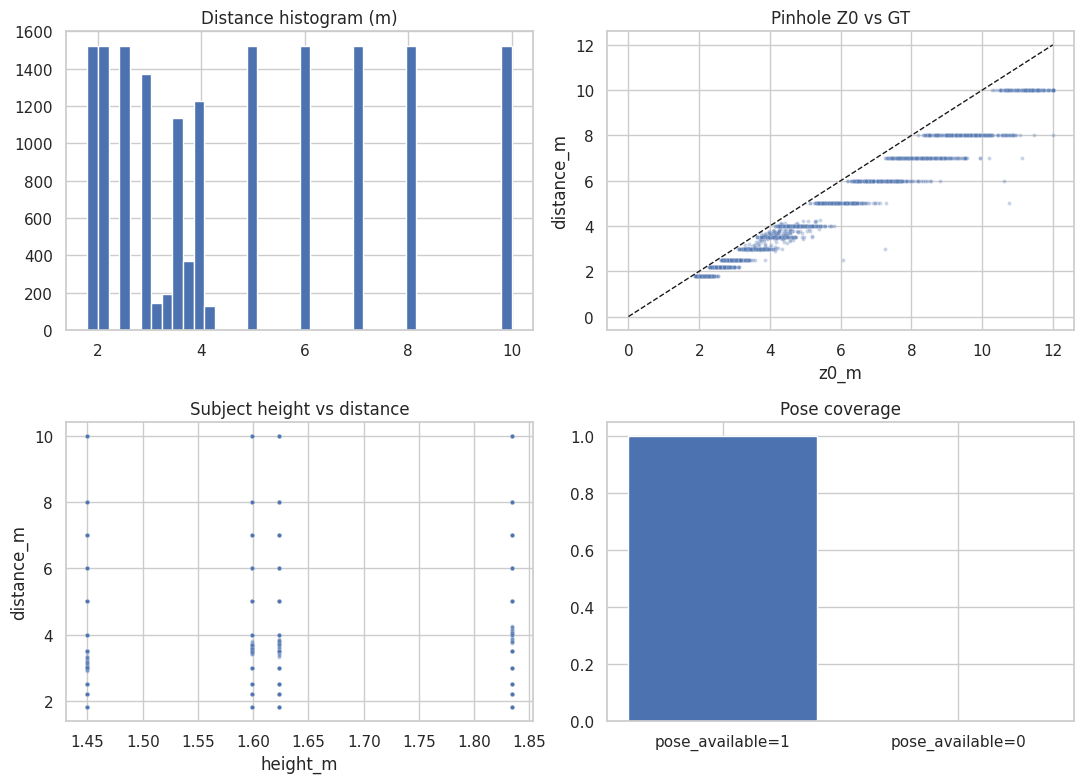

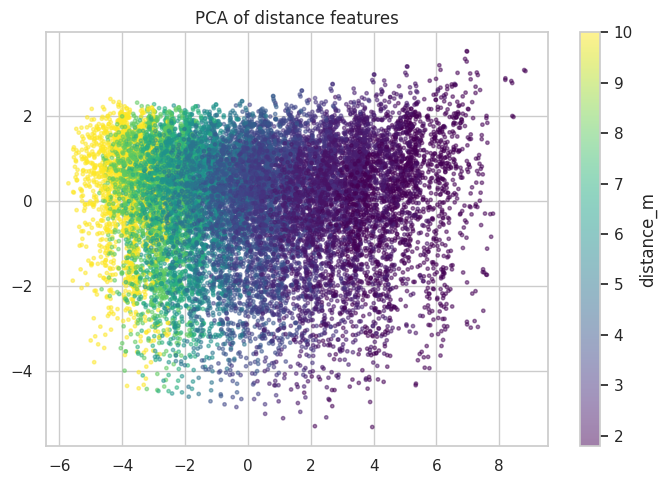

In [28]:
save_table(df["distance_m"].describe().to_frame("distance_m"), "eda_distance")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
df["distance_m"].hist(bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Distance histogram (m)")
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=SEED), x="z0_m", y="distance_m", alpha=0.3, s=8, ax=axes[0, 1])
axes[0, 1].plot([0, 12], [0, 12], "k--", lw=1)
axes[0, 1].set_title("Pinhole Z0 vs GT")
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=SEED), x="height_m", y="distance_m", alpha=0.3, s=8, ax=axes[1, 0])
axes[1, 0].set_title("Subject height vs distance")
pose_rate = float(df["pose_available"].mean())
axes[1, 1].bar(["pose_available=1", "pose_available=0"], [pose_rate, 1 - pose_rate])
axes[1, 1].set_title("Pose coverage")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eda_distance_overview.png", dpi=140)
plt.show()

scaler = StandardScaler()
X_feat = df[FEATURE_NAMES].to_numpy(dtype=np.float32)
coords = PCA(n_components=2, random_state=SEED).fit_transform(scaler.fit_transform(X_feat))
pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "distance_m": df["distance_m"].values})
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pca_df["PC1"], pca_df["PC2"], c=pca_df["distance_m"], cmap="viridis", s=6, alpha=0.5)
plt.colorbar(sc, ax=ax, label="distance_m")
ax.set_title("PCA of distance features")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pca_distance_features.png", dpi=140)
plt.show()

## 4. Train / val / test split by subject

`GroupShuffleSplit` holds out entire subjects so augmented frames from the same person do not leak.

In [29]:
# --- Splits: hold out subjects to avoid leakage ------------------------------
feature_cols = FEATURE_NAMES
X = df[feature_cols].to_numpy(np.float32)
y = df["distance_m"].to_numpy(np.float32)
z0 = df["z0_m"].to_numpy(np.float32)
groups = df["subject"].to_numpy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))
X_tr, X_te = X[train_idx], X[test_idx]
y_tr, y_te = y[train_idx], y[test_idx]
z0_tr, z0_te = z0[train_idx], z0[test_idx]

print("Train:", len(train_idx), "Test:", len(test_idx))
print("Train subjects:", sorted(set(groups[train_idx])))
print("Test subjects:", sorted(set(groups[test_idx])))

Train: 11226 Test: 5544
Train subjects: ['TDB_001_F', 'TDB_003_M', 'TDB_004_F']
Test subjects: ['TDB_002_F']


## 5. Model definitions and training loop

`ResidualDistanceMLP` matches the live loader. Training uses early stopping on validation MAE.

In [30]:
# --- Metrics + experiment bookkeeping ----------------------------------------
def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    return {
        "mae": float(np.mean(np.abs(err))),
        "medae": float(np.median(np.abs(err))),
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mean_rel_err": float(np.mean(np.abs(err) / np.clip(y_true, 1e-3, None))),
    }


class ResidualDistanceMLP(nn.Module):
    def __init__(self, in_dim: int = 16, hidden=(64, 32)):
        super().__init__()
        layers: List[nn.Module] = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(inplace=True), nn.Dropout(0.1)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, x):
        return self.net(x).squeeze(-1)


class AbsoluteMLP(nn.Module):
    def __init__(self, in_dim: int = 16, hidden=(64, 32)):
        super().__init__()
        layers: List[nn.Module] = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(inplace=True), nn.Dropout(0.1)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


LEDGER: List[Dict[str, Any]] = []


def save_torch_experiment(exp_id: str, approach: str, model: nn.Module, metrics: dict, extra: dict | None = None):
    out = MODELS_DIR / exp_id
    out.mkdir(parents=True, exist_ok=True)
    weights = out / "model.pt"
    torch.save(model.state_dict(), weights)
    # Also refresh the live-inference alias used by Django
    torch.save(model.state_dict(), MODELS_DIR / "distance_nn.pt")
    meta = {
        "experiment_id": exp_id,
        "approach": approach,
        "dataset": DOI,
        "dataset_name": "Human tracking dataset of 3D anatomical landmarks and pose keypoints",
        "feature_names": FEATURE_NAMES,
        "metrics_test": metrics,
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "formula": "Z = Z0 * exp(delta)" if "Residual" in approach or "residual" in approach.lower() or "log-Huber" in approach else approach,
        **(extra or {}),
    }
    with (out / "metadata.json").open("w") as f:
        json.dump(meta, f, indent=2)
    LEDGER.append({"experiment_id": exp_id, "approach": approach, **metrics, "weights": str(weights)})
    print(json.dumps(meta, indent=2)[:800])
    return meta

In [31]:
def train_residual_mlp(
    X_tr, z0_tr, y_tr, X_va, z0_va, y_va,
    *,
    exp_id: str,
    loss_fn,
    max_epochs: int = MAX_EPOCHS,
    patience: int = PATIENCE,
    init_state: Optional[Dict[str, torch.Tensor]] = None,
) -> Tuple[ResidualDistanceMLP, Dict[str, float], List[Dict[str, float]]]:
    model = ResidualDistanceMLP(len(FEATURE_NAMES), HIDDEN).to(DEVICE)
    if init_state is not None:
        model.load_state_dict(init_state)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    train_ds = TensorDataset(
        torch.from_numpy(X_tr), torch.from_numpy(z0_tr), torch.from_numpy(y_tr)
    )
    val_ds = TensorDataset(
        torch.from_numpy(X_va), torch.from_numpy(z0_va), torch.from_numpy(y_va)
    )
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
    best_mae = float("inf")
    best_state = None
    bad = 0
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, z0b, yb in train_loader:
            xb, z0b, yb = xb.to(DEVICE), z0b.to(DEVICE), yb.to(DEVICE)
            delta = model(xb)
            pred = z0b * torch.exp(delta)
            loss = loss_fn(pred, yb, z0b)
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        preds = []
        with torch.no_grad():
            for xb, z0b, yb in val_loader:
                xb, z0b = xb.to(DEVICE), z0b.to(DEVICE)
                pred = z0b * torch.exp(model(xb))
                preds.append(pred.cpu().numpy())
        val_pred = np.concatenate(preds)
        val_mae = float(np.mean(np.abs(val_pred - y_va)))
        history.append({"epoch": epoch, "val_mae": val_mae})
        print(f"[{exp_id}] epoch {epoch} val_mae={val_mae:.4f}")
        if val_mae < best_mae:
            best_mae = val_mae
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, {"val_mae": best_mae}, history


def smooth_l1_log(pred, yb, z0b):
    return nn.functional.smooth_l1_loss(torch.log(pred.clamp_min(1e-3)), torch.log(yb.clamp_min(1e-3)))


def huber_log(pred, yb, z0b, delta=0.15):
    return nn.functional.huber_loss(torch.log(pred.clamp_min(1e-3)), torch.log(yb.clamp_min(1e-3)), delta=delta)

## 6. Experiments

In [32]:
# Validation split from train subjects (15% rows)
n = len(X_tr)
idx = np.arange(n)
rng = np.random.default_rng(SEED)
rng.shuffle(idx)
n_val = max(1, int(0.15 * n))
val_idx, tr_idx = idx[:n_val], idx[n_val:]
X_train, X_val = X_tr[tr_idx], X_tr[val_idx]
z0_train, z0_val = z0_tr[tr_idx], z0_tr[val_idx]
y_train, y_val = y_tr[tr_idx], y_tr[val_idx]

In [33]:
exp_id = "dist_exp01_pinhole_z0"
register_hyperparams(exp_id, [{"parameter": "model", "value": "none", "meaning": "Use z0 only"}])
pred = z0_te
metrics = regression_metrics(y_te, pred)
LEDGER.append({"experiment_id": exp_id, "approach": "Pinhole Z0", **metrics})
save_table(pd.DataFrame([metrics]), f"metrics_{exp_id}")

,value,meaning
parameter,,
model,none,Use z0 only


,mae,medae,rmse,mean_rel_err
0,0.79318,0.624901,0.969226,0.166453


In [34]:
exp_id = "dist_exp02_ridge"
register_hyperparams(exp_id, [{"parameter": "alpha", "value": 1.0, "meaning": "L2 strength"}])
ridge = Ridge(alpha=1.0)
ridge.fit(X_tr, y_tr)
pred = ridge.predict(X_te)
metrics = regression_metrics(y_te, pred)
LEDGER.append({"experiment_id": exp_id, "approach": "Ridge", **metrics})

,value,meaning
parameter,,
alpha,1.0,L2 strength


In [36]:
exp_id = "dist_exp03_residual_mlp"
register_hyperparams(exp_id, [
    {"parameter": "hidden", "value": str(HIDDEN), "meaning": "MLP shape"},
    {"parameter": "loss", "value": "smooth_l1_log", "meaning": "Log-space robust loss"},
    {"parameter": "patience", "value": PATIENCE, "meaning": "Early stopping"},
])
model, val_info, hist = train_residual_mlp(
    X_train, z0_train, y_train, X_val, z0_val, y_val, exp_id=exp_id, loss_fn=lambda p, y, z: smooth_l1_log(p, y, z)
)
model.eval()
with torch.no_grad():
    delta = model(torch.from_numpy(X_te).to(DEVICE)).cpu().numpy()
pred = z0_te * np.exp(delta)
metrics = regression_metrics(y_te, pred)
save_table(pd.DataFrame(hist), f"history_{exp_id}")
save_torch_experiment(exp_id, "Residual MLP - SAMS Z=Z0*exp(delta)", model, metrics)

,value,meaning
parameter,,
hidden,"(64, 32)",MLP shape
loss,smooth_l1_log,Log-space robust loss
patience,10,Early stopping


[dist_exp03_residual_mlp] epoch 1 val_mae=0.3039
[dist_exp03_residual_mlp] epoch 2 val_mae=0.2707
[dist_exp03_residual_mlp] epoch 3 val_mae=0.2749
[dist_exp03_residual_mlp] epoch 4 val_mae=0.2639
[dist_exp03_residual_mlp] epoch 5 val_mae=0.2623
[dist_exp03_residual_mlp] epoch 6 val_mae=0.2625
[dist_exp03_residual_mlp] epoch 7 val_mae=0.2616
[dist_exp03_residual_mlp] epoch 8 val_mae=0.2639
[dist_exp03_residual_mlp] epoch 9 val_mae=0.2566
[dist_exp03_residual_mlp] epoch 10 val_mae=0.2666
[dist_exp03_residual_mlp] epoch 11 val_mae=0.2538
[dist_exp03_residual_mlp] epoch 12 val_mae=0.2521
[dist_exp03_residual_mlp] epoch 13 val_mae=0.2523
[dist_exp03_residual_mlp] epoch 14 val_mae=0.2513
[dist_exp03_residual_mlp] epoch 15 val_mae=0.2496
[dist_exp03_residual_mlp] epoch 16 val_mae=0.2495
[dist_exp03_residual_mlp] epoch 17 val_mae=0.2484
[dist_exp03_residual_mlp] epoch 18 val_mae=0.2470
[dist_exp03_residual_mlp] epoch 19 val_mae=0.2446
[dist_exp03_residual_mlp] epoch 20 val_mae=0.2434
[dist_exp

,epoch,val_mae
0,1,0.303945
1,2,0.270739
2,3,0.274857
3,4,0.263851
4,5,0.262286
...,...,...
75,76,0.207944
76,77,0.202383
77,78,0.202224
78,79,0.202239


{
  "experiment_id": "dist_exp03_residual_mlp",
  "approach": "Residual MLP - SAMS Z=Z0*exp(delta)",
  "dataset": "10.17632/493s6f753v.2",
  "dataset_name": "Human tracking dataset of 3D anatomical landmarks and pose keypoints",
  "feature_names": [
    "rel_h",
    "rel_w",
    "aspect",
    "cx_norm",
    "cy_norm",
    "bottom_y_norm",
    "inv_rel_h",
    "log_z0",
    "det_conf",
    "pose_available",
    "pose_height_rel",
    "shoulder_width_rel",
    "hip_width_rel",
    "torso_rel",
    "pose_conf_mean",
    "pose_inv_height"
  ],
  "metrics_test": {
    "mae": 0.2357960780074586,
    "medae": 0.16891813278198242,
    "rmse": 0.3198263224917325,
    "mean_rel_err": 0.04916272194227722
  },
  "timestamp_utc": "2026-10-08T13:29:50.778308+00:00",
  "formula": "Z = Z0 * exp(delta)"
}


{'experiment_id': 'dist_exp03_residual_mlp',
 'approach': 'Residual MLP - SAMS Z=Z0*exp(delta)',
 'dataset': '10.17632/493s6f753v.2',
 'dataset_name': 'Human tracking dataset of 3D anatomical landmarks and pose keypoints',
 'feature_names': ['rel_h',
  'rel_w',
  'aspect',
  'cx_norm',
  'cy_norm',
  'bottom_y_norm',
  'inv_rel_h',
  'log_z0',
  'det_conf',
  'pose_available',
  'pose_height_rel',
  'shoulder_width_rel',
  'hip_width_rel',
  'torso_rel',
  'pose_conf_mean',
  'pose_inv_height'],
 'metrics_test': {'mae': 0.2357960780074586,
  'medae': 0.16891813278198242,
  'rmse': 0.3198263224917325,
  'mean_rel_err': 0.04916272194227722},
 'timestamp_utc': '2026-10-08T13:29:50.778308+00:00',
 'formula': 'Z = Z0 * exp(delta)'}

In [37]:
exp_id = "dist_exp04_absolute_mlp"
register_hyperparams(exp_id, [{"parameter": "target", "value": "Z directly", "meaning": "No Z0 residual"}])
abs_model = AbsoluteMLP(len(FEATURE_NAMES), HIDDEN).to(DEVICE)
# short train for benchmark
opt = torch.optim.AdamW(abs_model.parameters(), lr=LR)
for epoch in range(30):
    abs_model.train()
    xb = torch.from_numpy(X_train).to(DEVICE)
    yb = torch.from_numpy(y_train).to(DEVICE)
    pred = abs_model(xb)
    loss = nn.functional.smooth_l1_loss(pred, yb)
    opt.zero_grad()
    loss.backward()
    opt.step()
abs_model.eval()
with torch.no_grad():
    pred = abs_model(torch.from_numpy(X_te).to(DEVICE)).cpu().numpy()
metrics = regression_metrics(y_te, pred)
save_torch_experiment(exp_id, "Absolute MLP - direct Z regression", abs_model, metrics)

,value,meaning
parameter,,
target,Z directly,No Z0 residual


{
  "experiment_id": "dist_exp04_absolute_mlp",
  "approach": "Absolute MLP - direct Z regression",
  "dataset": "10.17632/493s6f753v.2",
  "dataset_name": "Human tracking dataset of 3D anatomical landmarks and pose keypoints",
  "feature_names": [
    "rel_h",
    "rel_w",
    "aspect",
    "cx_norm",
    "cy_norm",
    "bottom_y_norm",
    "inv_rel_h",
    "log_z0",
    "det_conf",
    "pose_available",
    "pose_height_rel",
    "shoulder_width_rel",
    "hip_width_rel",
    "torso_rel",
    "pose_conf_mean",
    "pose_inv_height"
  ],
  "metrics_test": {
    "mae": 2.874271429075307,
    "medae": 2.220701575279236,
    "rmse": 3.636563432178763,
    "mean_rel_err": 0.5005927565104165
  },
  "timestamp_utc": "2026-10-08T13:29:51.944191+00:00",
  "formula": "Absolute MLP - direct Z regre


{'experiment_id': 'dist_exp04_absolute_mlp',
 'approach': 'Absolute MLP - direct Z regression',
 'dataset': '10.17632/493s6f753v.2',
 'dataset_name': 'Human tracking dataset of 3D anatomical landmarks and pose keypoints',
 'feature_names': ['rel_h',
  'rel_w',
  'aspect',
  'cx_norm',
  'cy_norm',
  'bottom_y_norm',
  'inv_rel_h',
  'log_z0',
  'det_conf',
  'pose_available',
  'pose_height_rel',
  'shoulder_width_rel',
  'hip_width_rel',
  'torso_rel',
  'pose_conf_mean',
  'pose_inv_height'],
 'metrics_test': {'mae': 2.874271429075307,
  'medae': 2.220701575279236,
  'rmse': 3.636563432178763,
  'mean_rel_err': 0.5005927565104165},
 'timestamp_utc': '2026-10-08T13:29:51.944191+00:00',
 'formula': 'Absolute MLP - direct Z regression'}

In [39]:
exp_id = "dist_exp05_residual_pose_only"
mask_tr = X_tr[:, FEATURE_NAMES.index("pose_available")] > 0.5
mask_te = X_te[:, FEATURE_NAMES.index("pose_available")] > 0.5
X_p_tr, z0_p_tr, y_p_tr = X_tr[mask_tr], z0_tr[mask_tr], y_tr[mask_tr]
X_p_te, z0_p_te, y_p_te = X_te[mask_te], z0_te[mask_te], y_te[mask_te]
model, _, hist = train_residual_mlp(
    X_p_tr, z0_p_tr, y_p_tr, X_p_tr[:500], z0_p_tr[:500], y_p_tr[:500], exp_id=exp_id, loss_fn=lambda p, y, z: smooth_l1_log(p, y, z)
)
model.eval()
with torch.no_grad():
    delta = model(torch.from_numpy(X_p_te).to(DEVICE)).cpu().numpy()
pred = z0_p_te * np.exp(delta)
metrics = regression_metrics(y_p_te, pred)
save_torch_experiment(exp_id, "Residual MLP - pose_available==1 subset", model, metrics)

[dist_exp05_residual_pose_only] epoch 1 val_mae=0.3625
[dist_exp05_residual_pose_only] epoch 2 val_mae=0.2824
[dist_exp05_residual_pose_only] epoch 3 val_mae=0.2815
[dist_exp05_residual_pose_only] epoch 4 val_mae=0.2777
[dist_exp05_residual_pose_only] epoch 5 val_mae=0.2802
[dist_exp05_residual_pose_only] epoch 6 val_mae=0.2707
[dist_exp05_residual_pose_only] epoch 7 val_mae=0.2666
[dist_exp05_residual_pose_only] epoch 8 val_mae=0.2660
[dist_exp05_residual_pose_only] epoch 9 val_mae=0.2587
[dist_exp05_residual_pose_only] epoch 10 val_mae=0.2563
[dist_exp05_residual_pose_only] epoch 11 val_mae=0.2554
[dist_exp05_residual_pose_only] epoch 12 val_mae=0.2507
[dist_exp05_residual_pose_only] epoch 13 val_mae=0.2532
[dist_exp05_residual_pose_only] epoch 14 val_mae=0.2453
[dist_exp05_residual_pose_only] epoch 15 val_mae=0.2493
[dist_exp05_residual_pose_only] epoch 16 val_mae=0.2446
[dist_exp05_residual_pose_only] epoch 17 val_mae=0.2467
[dist_exp05_residual_pose_only] epoch 18 val_mae=0.2387
[

{'experiment_id': 'dist_exp05_residual_pose_only',
 'approach': 'Residual MLP - pose_available==1 subset',
 'dataset': '10.17632/493s6f753v.2',
 'dataset_name': 'Human tracking dataset of 3D anatomical landmarks and pose keypoints',
 'feature_names': ['rel_h',
  'rel_w',
  'aspect',
  'cx_norm',
  'cy_norm',
  'bottom_y_norm',
  'inv_rel_h',
  'log_z0',
  'det_conf',
  'pose_available',
  'pose_height_rel',
  'shoulder_width_rel',
  'hip_width_rel',
  'torso_rel',
  'pose_conf_mean',
  'pose_inv_height'],
 'metrics_test': {'mae': 0.23208976765989742,
  'medae': 0.1724759340286255,
  'rmse': 0.3106687093527097,
  'mean_rel_err': 0.0486050062241796},
 'timestamp_utc': '2026-10-08T13:30:46.576474+00:00',
 'formula': 'Z = Z0 * exp(delta)'}

In [41]:
exp_id = "dist_exp06_residual_log_huber"
model, _, hist = train_residual_mlp(
    X_train, z0_train, y_train, X_val, z0_val, y_val, exp_id=exp_id, loss_fn=lambda p, y, z: huber_log(p, y, z)
)
model.eval()
with torch.no_grad():
    delta = model(torch.from_numpy(X_te).to(DEVICE)).cpu().numpy()
pred = z0_te * np.exp(delta)
metrics = regression_metrics(y_te, pred)
save_torch_experiment(exp_id, "Residual MLP - Huber loss on log(Z)", model, metrics)

[dist_exp06_residual_log_huber] epoch 1 val_mae=0.3100
[dist_exp06_residual_log_huber] epoch 2 val_mae=0.2855
[dist_exp06_residual_log_huber] epoch 3 val_mae=0.2728
[dist_exp06_residual_log_huber] epoch 4 val_mae=0.2648
[dist_exp06_residual_log_huber] epoch 5 val_mae=0.2640
[dist_exp06_residual_log_huber] epoch 6 val_mae=0.2627
[dist_exp06_residual_log_huber] epoch 7 val_mae=0.2618
[dist_exp06_residual_log_huber] epoch 8 val_mae=0.2596
[dist_exp06_residual_log_huber] epoch 9 val_mae=0.2578
[dist_exp06_residual_log_huber] epoch 10 val_mae=0.2554
[dist_exp06_residual_log_huber] epoch 11 val_mae=0.2561
[dist_exp06_residual_log_huber] epoch 12 val_mae=0.2554
[dist_exp06_residual_log_huber] epoch 13 val_mae=0.2528
[dist_exp06_residual_log_huber] epoch 14 val_mae=0.2503
[dist_exp06_residual_log_huber] epoch 15 val_mae=0.2505
[dist_exp06_residual_log_huber] epoch 16 val_mae=0.2477
[dist_exp06_residual_log_huber] epoch 17 val_mae=0.2498
[dist_exp06_residual_log_huber] epoch 18 val_mae=0.2457
[

{'experiment_id': 'dist_exp06_residual_log_huber',
 'approach': 'Residual MLP - Huber loss on log(Z)',
 'dataset': '10.17632/493s6f753v.2',
 'dataset_name': 'Human tracking dataset of 3D anatomical landmarks and pose keypoints',
 'feature_names': ['rel_h',
  'rel_w',
  'aspect',
  'cx_norm',
  'cy_norm',
  'bottom_y_norm',
  'inv_rel_h',
  'log_z0',
  'det_conf',
  'pose_available',
  'pose_height_rel',
  'shoulder_width_rel',
  'hip_width_rel',
  'torso_rel',
  'pose_conf_mean',
  'pose_inv_height'],
 'metrics_test': {'mae': 0.22127512888646916,
  'medae': 0.14919495582580566,
  'rmse': 0.3121001845451219,
  'mean_rel_err': 0.044960231566134136},
 'timestamp_utc': '2026-10-08T13:31:41.427911+00:00',
 'formula': 'Z = Z0 * exp(delta)'}

## 7. Compare experiments and export live artifacts

,experiment_id,approach,mae,medae,rmse,mean_rel_err,weights
5,dist_exp06_residual_log_huber,Residual MLP - Huber loss on log(Z),0.221275,0.149195,0.312100,0.044960,/content/drive/MyDrive/SAMS/models/vision/dist...
4,dist_exp05_residual_pose_only,Residual MLP - pose_available==1 subset,0.232090,0.172476,0.310669,0.048605,/content/drive/MyDrive/SAMS/models/vision/dist...
2,dist_exp03_residual_mlp,Residual MLP - SAMS Z=Z0*exp(delta),0.235796,0.168918,0.319826,0.049163,/content/drive/MyDrive/SAMS/models/vision/dist...
1,dist_exp02_ridge,Ridge,0.364725,0.320261,0.458820,0.086639,NaN
0,dist_exp01_pinhole_z0,Pinhole Z0,0.793180,0.624901,0.969226,0.166453,NaN
3,dist_exp04_absolute_mlp,Absolute MLP - direct Z regression,2.874271,2.220702,3.636563,0.500593,/content/drive/MyDrive/SAMS/models/vision/dist...


Best MAE: dist_exp06_residual_log_huber 0.22127512888646916
Wrote calib.json and distance_nn.pt


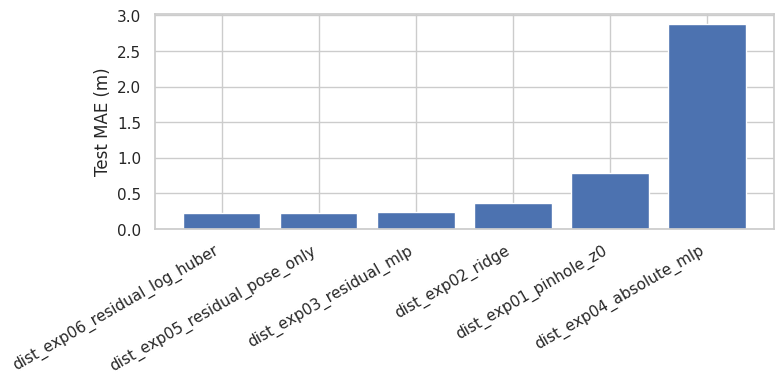

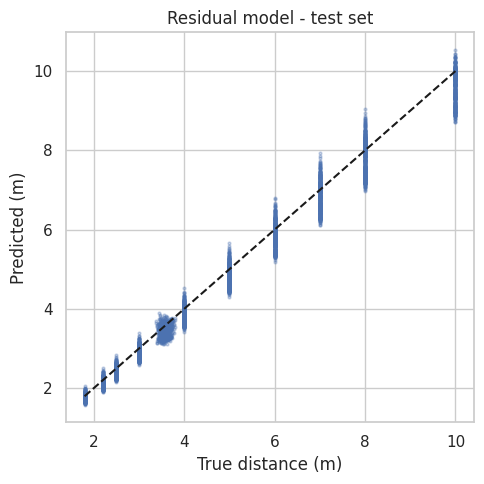

In [43]:
comparison = pd.DataFrame(LEDGER).sort_values("mae")
save_table(comparison, "experiment_comparison")
winner = comparison.iloc[0]
winner_id = winner["experiment_id"]
print("Best MAE:", winner_id, winner["mae"])

# Promote best residual weights to distance_nn.pt
residual_rows = comparison[comparison["experiment_id"].str.contains("residual")]
best_residual = residual_rows.iloc[0]["experiment_id"]
src = MODELS_DIR / best_residual / "model.pt"
torch.save(torch.load(src, map_location="cpu", weights_only=True), MODELS_DIR / "distance_nn.pt")

fy_px = float(np.median(fy_samples)) if fy_samples else FY_PX_DEFAULT
calib = {
    "fy_px": fy_px,
    # Image height fy was measured at, so the service can scale fy to its own frame size.
    "fy_image_h": float(np.median(fy_image_heights)) if fy_image_heights else None,
    "person_height_m": PERSON_HEIGHT_M,
    "tof_near_m": TOF_NEAR_M,
    "hidden": list(HIDDEN),
    "feature_names": FEATURE_NAMES,
    "best_experiment_id": best_residual,
    "dataset": DOI,
}
with open(MODELS_DIR / "calib.json", "w") as f:
    json.dump(calib, f, indent=2)
print("Wrote calib.json and distance_nn.pt")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparison["experiment_id"], comparison["mae"])
ax.tick_params(axis="x", labelrotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_ylabel("Test MAE (m)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_mae.png", dpi=140)
plt.show()

best_res_id = residual_rows.iloc[0]["experiment_id"]
res_model = ResidualDistanceMLP(len(FEATURE_NAMES), HIDDEN).to(DEVICE)
res_model.load_state_dict(torch.load(MODELS_DIR / best_res_id / "model.pt", map_location=DEVICE, weights_only=True))
res_model.eval()
with torch.no_grad():
    residual_delta = res_model(torch.from_numpy(X_te).to(DEVICE)).cpu().numpy()
residual_pred = z0_te * np.exp(residual_delta)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_te, residual_pred, s=4, alpha=0.3)
ax.plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], "k--")
ax.set_xlabel("True distance (m)")
ax.set_ylabel("Predicted (m)")
ax.set_title("Residual model - test set")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "residual_pred_vs_true.png", dpi=140)
plt.show()

## 8. Fine-tune on this site's labelled rows

The public dataset never saw this camera or this floor. Rows measured on site (a person standing at a taped distance, or the ToF reading for the person in its beam) fine-tune the promoted residual network. The live service serves `models/vision/distance/site/` when it exists, ahead of the public experiments.

Put the rows in `datasets/vision/distance/site_labels.csv` (under `MyDrive/SAMS/` in Colab) with these columns: every name in `FEATURE_NAMES`, then `z0_m` (or `log_z0`), then `distance_m`. The cell below prints the header. Without that file this section only reports that there is no site data.

The site model is written only when it beats the public model on held-out site rows.

In [ ]:
SITE_CSV = DRIVE_ROOT / "datasets" / "vision" / "distance" / "site_labels.csv"
SITE_DIR = MODELS_DIR / "site"
print("Site CSV header:", ",".join(FEATURE_NAMES + ["z0_m", "distance_m"]))

if not SITE_CSV.exists():
    print(f"No site data at {SITE_CSV}. Live serving keeps {best_residual}.")
else:
    site = pd.read_csv(SITE_CSV)
    X_site = site[FEATURE_NAMES].to_numpy(dtype=np.float32)
    z0_col = site["z0_m"] if "z0_m" in site else np.exp(site["log_z0"])
    z0_site = np.asarray(z0_col, dtype=np.float32)
    y_site = site["distance_m"].to_numpy(dtype=np.float32)

    order = np.random.default_rng(SEED).permutation(len(site))
    n_hold = max(1, int(0.15 * len(site)))
    te_i, va_i, tr_i = order[:n_hold], order[n_hold : 2 * n_hold], order[2 * n_hold :]
    save_table(
        pd.DataFrame({"split": ["train", "val", "test"], "rows": [len(tr_i), len(va_i), len(te_i)]}).set_index("split"),
        "site_split",
    )

    base_state = torch.load(MODELS_DIR / best_residual / "model.pt", map_location=DEVICE, weights_only=True)
    site_model, _, site_hist = train_residual_mlp(
        X_site[tr_i], z0_site[tr_i], y_site[tr_i],
        X_site[va_i], z0_site[va_i], y_site[va_i],
        exp_id="dist_site_finetune",
        loss_fn=lambda p, y, z: smooth_l1_log(p, y, z),
        init_state=base_state,
    )

    base_model = ResidualDistanceMLP(len(FEATURE_NAMES), HIDDEN).to(DEVICE)
    base_model.load_state_dict(base_state)
    rows = []
    with torch.no_grad():
        for name, net in (("public " + best_residual, base_model), ("site fine-tune", site_model)):
            net.eval()
            delta = net(torch.from_numpy(X_site[te_i]).to(DEVICE)).cpu().numpy()
            rows.append({"model": name, **regression_metrics(y_site[te_i], z0_site[te_i] * np.exp(delta))})
    site_comparison = pd.DataFrame(rows).set_index("model")
    save_table(site_comparison, "site_comparison")

    site_metrics = site_comparison.loc["site fine-tune"].to_dict()
    if site_metrics["mae"] < site_comparison.iloc[0]["mae"]:
        SITE_DIR.mkdir(parents=True, exist_ok=True)
        torch.save(site_model.state_dict(), SITE_DIR / "model.pt")
        with open(SITE_DIR / "metadata.json", "w") as f:
            json.dump(
                {
                    "experiment_id": "dist_site_finetune",
                    "approach": f"Residual MLP fine-tuned from {best_residual} on site rows",
                    "formula": "Z = Z0 * exp(delta)",
                    "hidden": list(HIDDEN),
                    "feature_names": FEATURE_NAMES,
                    "source": str(SITE_CSV),
                    "rows": int(len(site)),
                    "metrics_test": site_metrics,
                    "public_metrics_test": site_comparison.iloc[0].to_dict(),
                    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                },
                f,
                indent=2,
            )
        print("Site model written to", SITE_DIR)
    else:
        print("Site fine-tune did not beat the public model on held-out site rows; nothing written.")

## 9. Limitations

1. Virtual long-range augmentation scales 2D keypoints; it is useful for training but not a physical simulator.
2. Only four subjects - test holdout can be a single person.
3. MediaPipe index layout differs from COCO-17 used live; features are aligned by name, not by raw keypoint order in deployment.
4. Pinhole fy is estimated per camera matrix; site calibration should replace `calib.json` on install.
5. Absolute and pinhole baselines are included for comparison, not for live export.